# Same-sample normalization

Use the same reference **S + EWSBI10**, direct targets **SBI**, **qqZZ**, and **SBI + qqZZ**, event weights, selections, and bins as notebook 02.

1. Normalize the reference event weights, measure the weighted means of `r_SBI` and `r_qqZZ`, and correct each ratio by its own mean.
2. Compare the original and corrected reweightings with the direct target on the **same histograms and ratio panels**.

For reference event $i$, define
$$
u_i=\frac{w_i}{\lambda_{\rm ref}},\qquad
\lambda_{\rm ref}=\sum_{i\in\mathrm{ref}}w_i,\qquad
Z_j=\sum_{i\in\mathrm{ref}}u_i r_j(x_i),\qquad
r_j^{\rm SSN}(x_i)=\frac{r_j(x_i)}{Z_j}.
$$
Then $\sum_{i\in\mathrm{ref}}u_i=1$ and $\sum_{i\in\mathrm{ref}}u_i r_j^{\rm SSN}(x_i)=1$ for each component. **The same reference events are used to estimate $Z_j$ and make the plots.** Each $Z_j$ is computed once over the full selected reference sample, including events outside the plotted ranges.

The plots show weighted yields and unit-area shapes for both variables. All ratio panels use **0.90–1.10**, the default for this project.

| Variable | Range | Bin width |
|---|---|---|
| `NN_disc_New` | −1 to 1 | 0.05 |
| `m4l_fsr` | 150 to 2000 GeV | 50 GeV |

## Setup

Use a CPU runtime. This uses the same compatible package versions as notebook 01. If setup reports a stale import, choose **Runtime → Restart session**, then **Run all**. The plotting helper is downloaded again and PNG/PDF export is checked before loading the ntuple.

In [1]:
%pip -q install "matplotlib==3.10.0" "mplhep==0.4.1" tables


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 57.0 MB/s eta 0:00:00


In [2]:

# Installing a package cannot replace a copy already loaded in this session.
import sys
from importlib.metadata import version

for package in ("matplotlib", "mplhep", "numpy", "pandas", "tables"):
    loaded = sys.modules.get(package)
    if loaded is not None and loaded.__version__ != version(package):
        raise RuntimeError(
            f"{package} changed on disk while it was loaded. "
            "Choose Runtime > Restart session, then Run all."
        )

from pathlib import Path
from urllib.request import urlretrieve
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import mplhep as hep
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    import utils as offshell_utils
else:
    drive.mount("/content/drive")
    urlretrieve(
        "https://raw.githubusercontent.com/rafaellopesdesa/offshell_reweighting/main/utils.py",
        "/content/offshell_utils.py",
    )
    import offshell_utils

# Reload the downloaded helper even if this Colab runtime was used before.
importlib.invalidate_caches()
importlib.reload(offshell_utils)
load_columns = offshell_utils.load_columns
plot_normalization_comparison = offshell_utils.plot_normalization_comparison
same_sample_covariance = offshell_utils.same_sample_covariance
normalize_histogram = offshell_utils.normalize_histogram
hep.style.use("ATLAS")
offshell_utils.check_plot_exports()
print(f"Matplotlib {matplotlib.__version__}; mplhep {hep.__version__}")
print("PNG and PDF export checks passed.")


Mounted at /content/drive
Matplotlib 3.10.0; mplhep 0.4.1
PNG and PDF export checks passed.


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/HZZ_OffShell")
DATA_PATH = PROJECT_DIR / "dataset_wDR_mean_origIndex.h5"
PLOT_DIR = PROJECT_DIR / "plots" / "03_same_sample_normalization"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

NN_BINS = np.linspace(-1.0, 1.0, 41)
M4L_BINS = np.arange(150.0, 2000.0 + 50.0, 50.0)
RATIO_YLIM = (0.90, 1.10)  # Project default for all ratio panels.

variables = [
    ("NN_disc_New", NN_BINS, "NN_disc_New", "Weighted yield / 0.05", "Normalized density"),
    ("m4l_fsr", M4L_BINS, r"$m_{4\ell}^{\mathrm{FSR}}$ [GeV]",
     "Weighted yield / 50 GeV", r"Normalized density [GeV$^{-1}$]"),
]

## Load the columns and compute sample yields

As in notebook 01, count and exclude rows with nonfinite `weight_kFact`, `NN_disc_New`, or `m4l_fsr`. This common finite-value selection defines the samples used throughout. Values outside the plotting ranges still contribute to the sample yields. The ratio branches are needed only on reference events.

In [4]:
data = load_columns(DATA_PATH, [
    "Type", "weight_kFact", "NN_disc_New", "m4l_fsr", "r_SBI", "r_qqZZ",
])
event_type = data["Type"]
weights = np.asarray(data["weight_kFact"], dtype=np.float64)
reference = np.isin(event_type, ["S", "EWSBI10"])
sbi = event_type == "SBI"
qqzz = event_type == "qqZZ"

finite = (np.isfinite(weights) & np.isfinite(data["NN_disc_New"])
          & np.isfinite(data["m4l_fsr"]))
for name, mask in [("Reference", reference), ("SBI", sbi), ("qqZZ", qqzz)]:
    print(f"{name}: excluding {np.count_nonzero(mask & ~finite):,} nonfinite rows")
reference &= finite
sbi &= finite
qqzz &= finite
target = sbi | qqzz

lambda_ref = weights[reference].sum()
lambda_sbi = weights[sbi].sum()
lambda_qqzz = weights[qqzz].sum()
if lambda_ref == 0:
    raise ValueError("The reference has zero signed yield; yield scaling is undefined.")

native_yields = []
for name, mask in [("Reference", reference), ("SBI", sbi), ("qqZZ", qqzz),
                   ("SBI + qqZZ", target)]:
    native_yields.append({
        "sample": name, "events": int(mask.sum()), "yield": weights[mask].sum(),
        "negative_weights": int(np.count_nonzero(weights[mask] < 0)),
    })
display(pd.DataFrame(native_yields).set_index("sample"))

Reference: excluding 0 nonfinite rows
SBI: excluding 0 nonfinite rows
qqZZ: excluding 0 nonfinite rows


,events,yield,negative_weights
sample,,,
Reference,3110759,91.773434,1333
SBI,1673988,359.285953,122
qqZZ,2643586,1651.317870,488161
SBI + qqZZ,4317574,2010.603823,488283


## Step 1: measure and correct the ratio normalization

The weights entering both $Z$ factors are the **normalized reference weights** `w_ref_normalized`, including their signs. Ratios are needed only on reference events. Apply $r_j/Z_j$ even for a small departure from one; there is no threshold for deciding whether to correct it.

The table reports each original weighted mean, its correction factor, and the corrected weighted mean. A zero or nonfinite $Z$ cannot define this normalization.

In [5]:
w_ref = weights[reference]
w_ref_normalized = w_ref / lambda_ref
r_sbi = np.asarray(data["r_SBI"][reference], dtype=np.float64)
r_qqzz = np.asarray(data["r_qqZZ"][reference], dtype=np.float64)
for name, ratio in [("r_SBI", r_sbi), ("r_qqZZ", r_qqzz)]:
    n_invalid = int(np.count_nonzero(~np.isfinite(ratio)))
    if n_invalid:
        raise ValueError(f"{name}: {n_invalid:,} nonfinite values on selected reference events")

Z_SBI = np.sum(w_ref_normalized * r_sbi)
Z_qqZZ = np.sum(w_ref_normalized * r_qqzz)
for name, value in [("Z_SBI", Z_SBI), ("Z_qqZZ", Z_qqZZ)]:
    if not np.isfinite(value) or value == 0:
        raise ValueError(f"{name} = {value}: same-sample normalization is undefined")

r_sbi_ssn = r_sbi / Z_SBI
r_qqzz_ssn = r_qqzz / Z_qqZZ
print(f"Sum of normalized reference weights: {w_ref_normalized.sum():.12f}")
normalization_checks = pd.DataFrame({
    "ratio": ["r_SBI", "r_qqZZ"],
    "Z_before": [Z_SBI, Z_qqZZ],
    "correction_1_over_Z": [1.0 / Z_SBI, 1.0 / Z_qqZZ],
    "weighted_mean_after": [np.sum(w_ref_normalized * r_sbi_ssn),
                            np.sum(w_ref_normalized * r_qqzz_ssn)],
}).set_index("ratio")
display(normalization_checks)

Sum of normalized reference weights: 1.000000000000


,Z_before,correction_1_over_Z,weighted_mean_after
ratio,,,
r_SBI,1.000214,0.999786,1.0
r_qqZZ,1.000877,0.999124,1.0


## Step 2: compare reweightings with and without same-sample normalization

The original reweighting is exactly the one from notebook 02. For the corrected combination, use
$$
w_i^{\rm SSN}=w_i\left[
\frac{\lambda_{\rm SBI}}{\lambda_{\rm ref}}\frac{r_{\rm SBI}(x_i)}{Z_{\rm SBI}}
+\frac{\lambda_{qqZZ}}{\lambda_{\rm ref}}\frac{r_{qqZZ}(x_i)}{Z_{qqZZ}}
\right].
$$

Correct the two components separately before adding them. **Full-sample yield closure after correction is enforced by construction**; agreement across bins still tests the shape. The table below retains the original yield comparison alongside the corrected one.

For a single component, the two unit-area shapes coincide because the constant $1/Z_j$ cancels when normalizing the histogram. The combined unit-area shape can change because the two components have different $Z_j$.

In [6]:
w_sbi_raw = w_ref * (lambda_sbi / lambda_ref) * r_sbi
w_qqzz_raw = w_ref * (lambda_qqzz / lambda_ref) * r_qqzz
w_sbi_ssn = w_ref * (lambda_sbi / lambda_ref) * r_sbi_ssn
w_qqzz_ssn = w_ref * (lambda_qqzz / lambda_ref) * r_qqzz_ssn

# Each list at the end retains the components on the same reference events.
# It is used to propagate the normalization and their shared MC uncertainty.
comparisons = [
    ("SBI_plus_qqZZ", "SBI + qqZZ", target,
     w_sbi_raw + w_qqzz_raw, w_sbi_ssn + w_qqzz_ssn, [w_sbi_ssn, w_qqzz_ssn]),
    ("SBI", "SBI", sbi, w_sbi_raw, w_sbi_ssn, [w_sbi_ssn]),
    ("qqZZ", "qqZZ", qqzz, w_qqzz_raw, w_qqzz_ssn, [w_qqzz_ssn]),
]

yield_closure = []
for tag, name, direct_mask, raw_weights, ssn_weights, components in comparisons:
    if not np.all(np.isfinite(raw_weights)) or not np.all(np.isfinite(ssn_weights)):
        raise ValueError(f"{name}: nonfinite weights after reweighting")
    direct_yield = weights[direct_mask].sum()
    raw_yield, ssn_yield = raw_weights.sum(), ssn_weights.sum()
    yield_closure.append({
        "sample": name, "direct_yield": direct_yield,
        "without_SSN": raw_yield, "with_SSN": ssn_yield,
        "without/direct": raw_yield / direct_yield if direct_yield != 0 else np.nan,
        "with/direct": ssn_yield / direct_yield if direct_yield != 0 else np.nan,
    })
display(pd.DataFrame(yield_closure).set_index("sample"))

,direct_yield,without_SSN,with_SSN,without/direct,with/direct
sample,,,,,
SBI + qqZZ,2010.603823,2012.129049,2010.603823,1.000759,1.0
SBI,359.285953,359.362774,359.285953,1.000214,1.0
qqZZ,1651.317870,1652.766275,1651.317870,1.000877,1.0


## Plot both reweightings against the direct target

Each upper panel contains the direct target plus both reweightings. The lower panel contains **two reweighted/direct curves**, sharing the same direct denominator and grey target-MC uncertainty band. Blue circles show the original reweighting; orange open squares show same-sample normalization. Values are calculated without clipping; only the displayed ratio range is fixed to 0.90–1.10. Zero-direct-yield bins are omitted from the ratio panel.

The original MC variance is $\sum w^2$. Corrected MC errors also propagate the fluctuation of the same-sample $Z$ factors, including correlations between components evaluated on the same reference events. The full bin covariance is used for the corrected unit-area shapes. These diagnostics hold the yield coefficients and stored ratios fixed; they do not include model uncertainty or correlations with the direct sample. The two reweighting curves share events and are correlated.

The selections, reweighting weights, and histograms are explicit below; the covariance propagation and plot formatting are in `utils.py`.

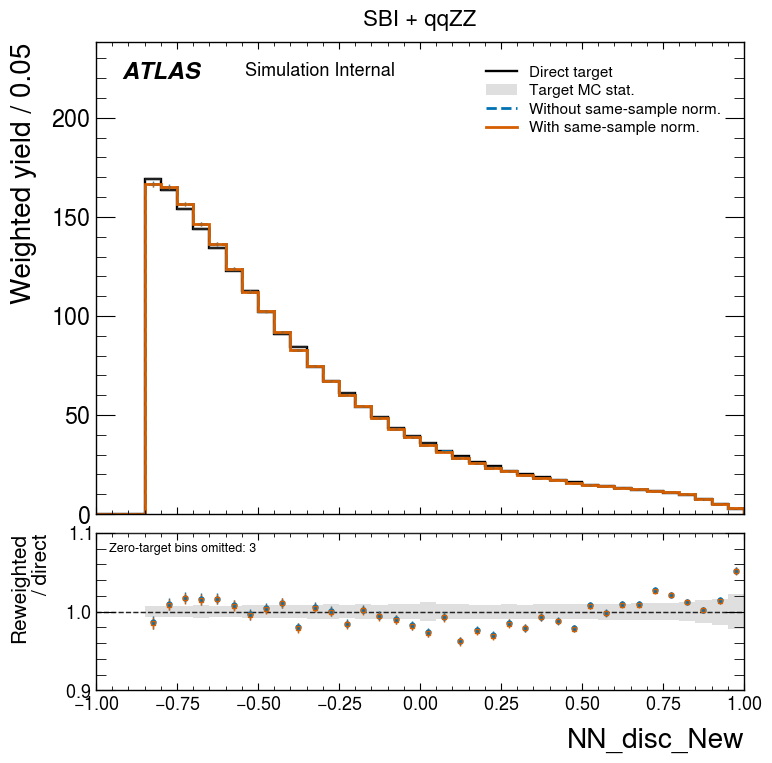

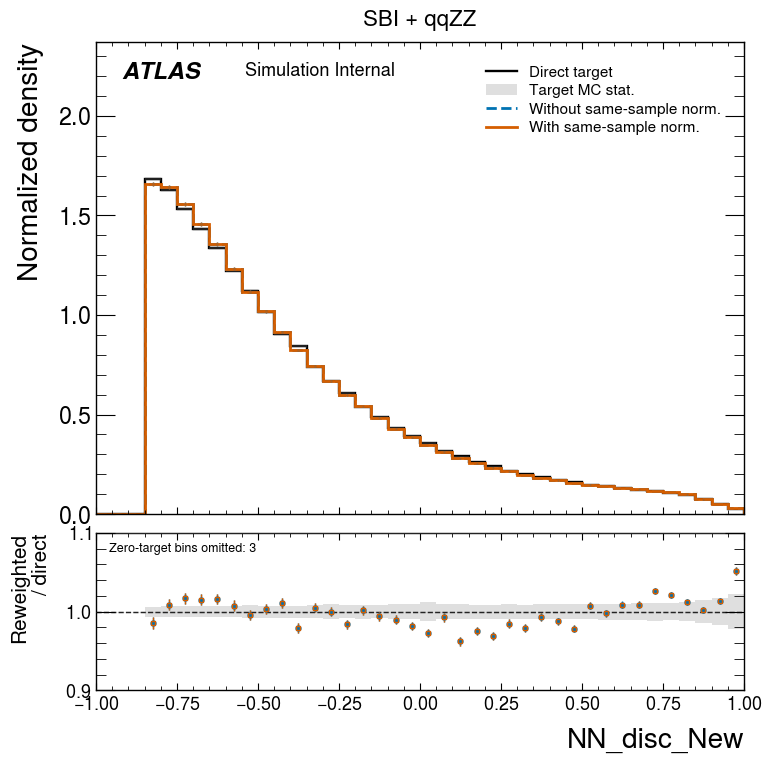

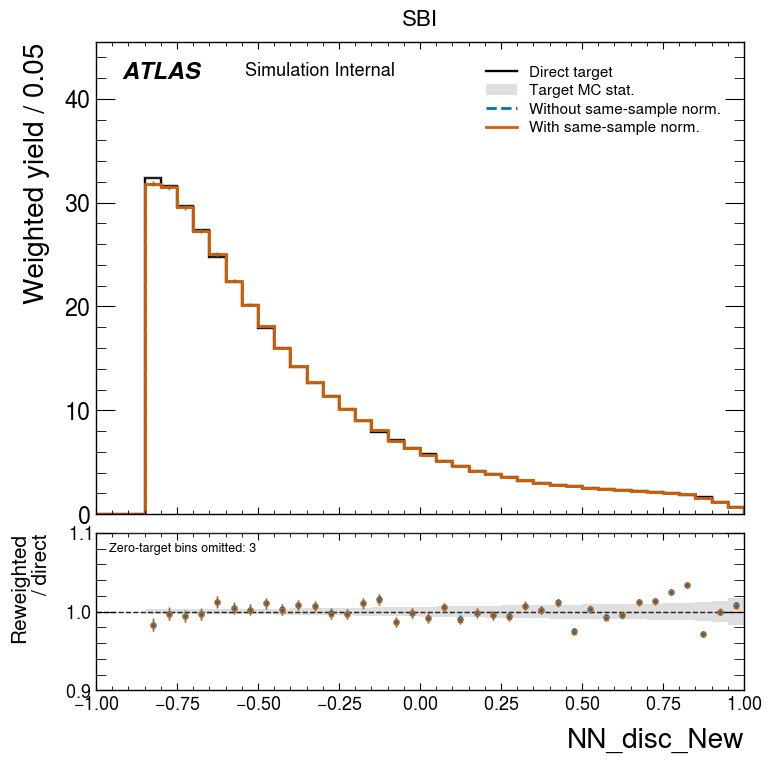

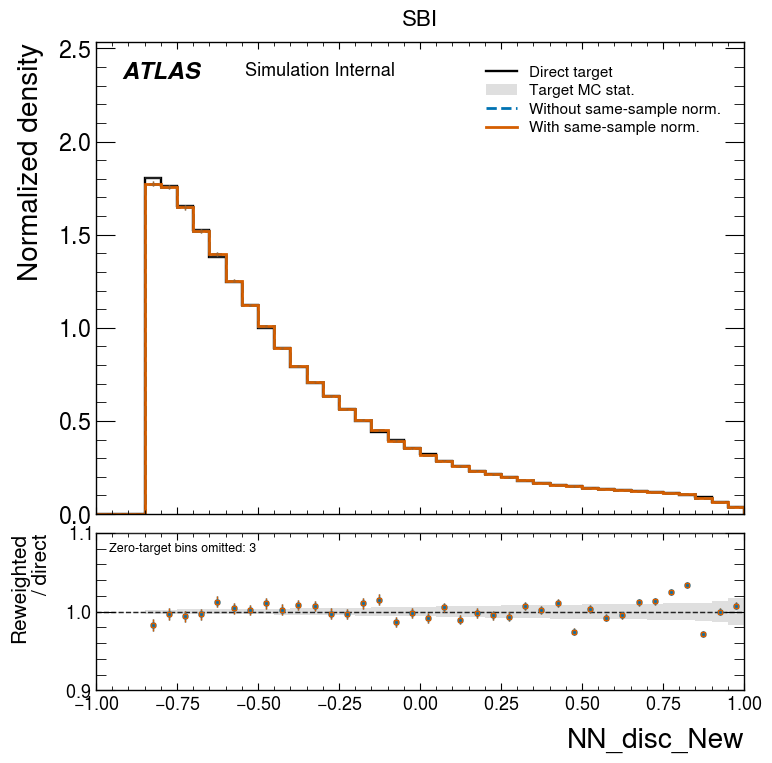

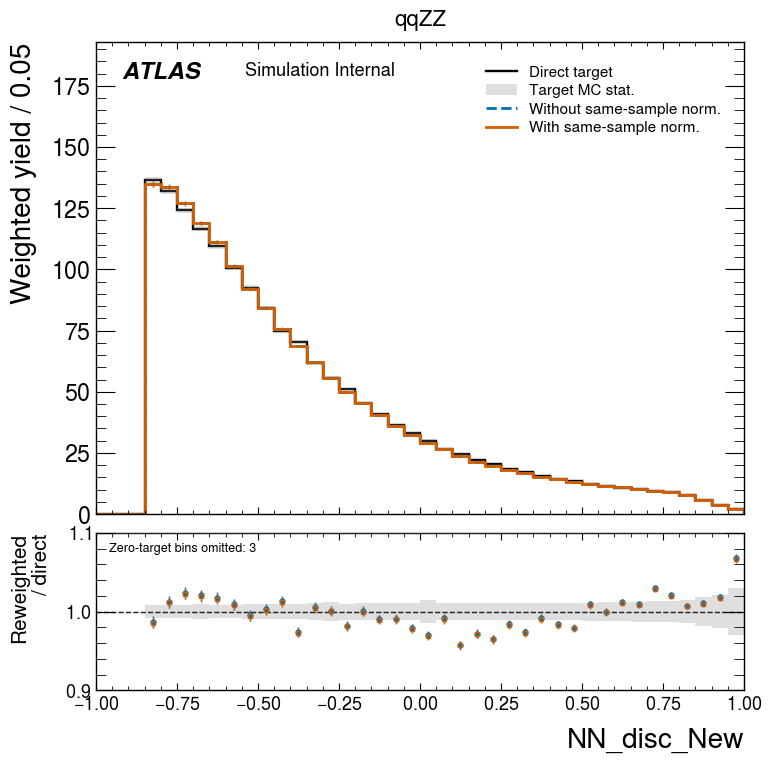

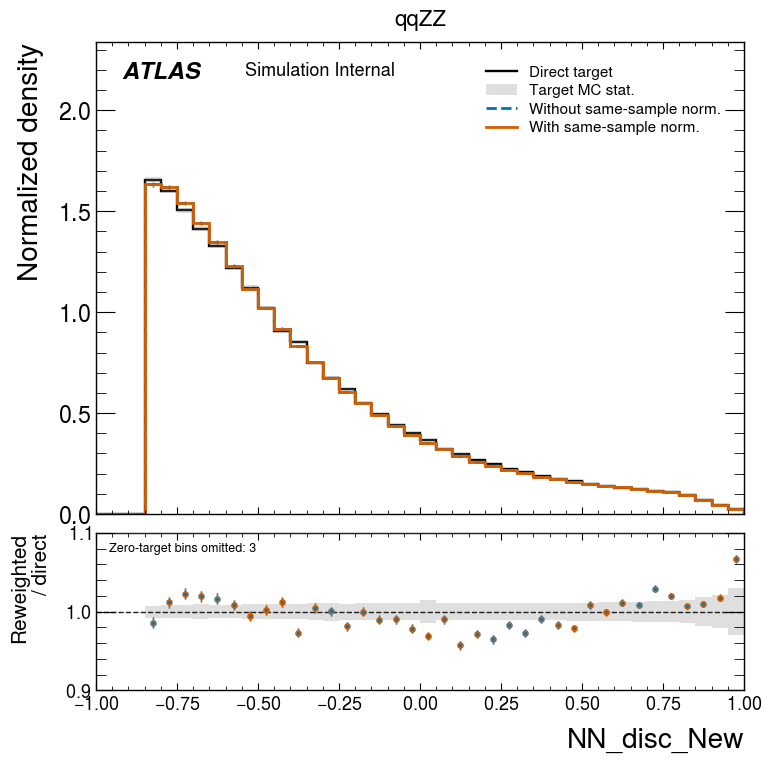

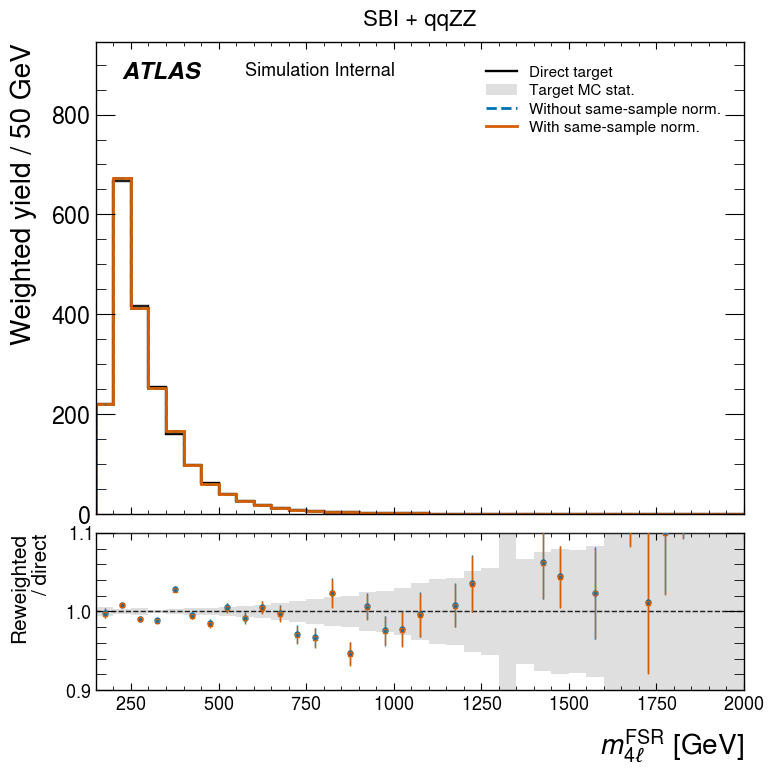

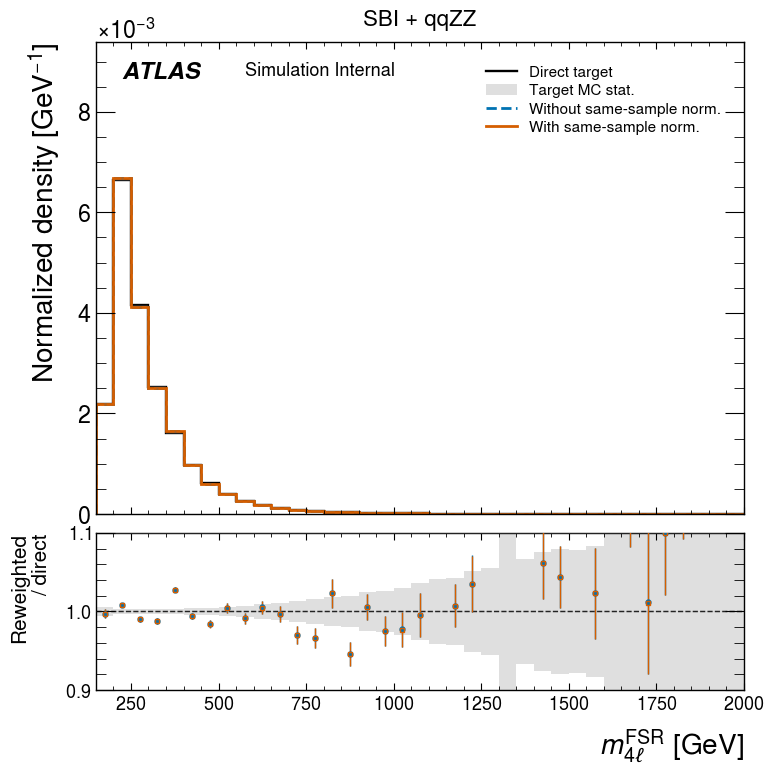

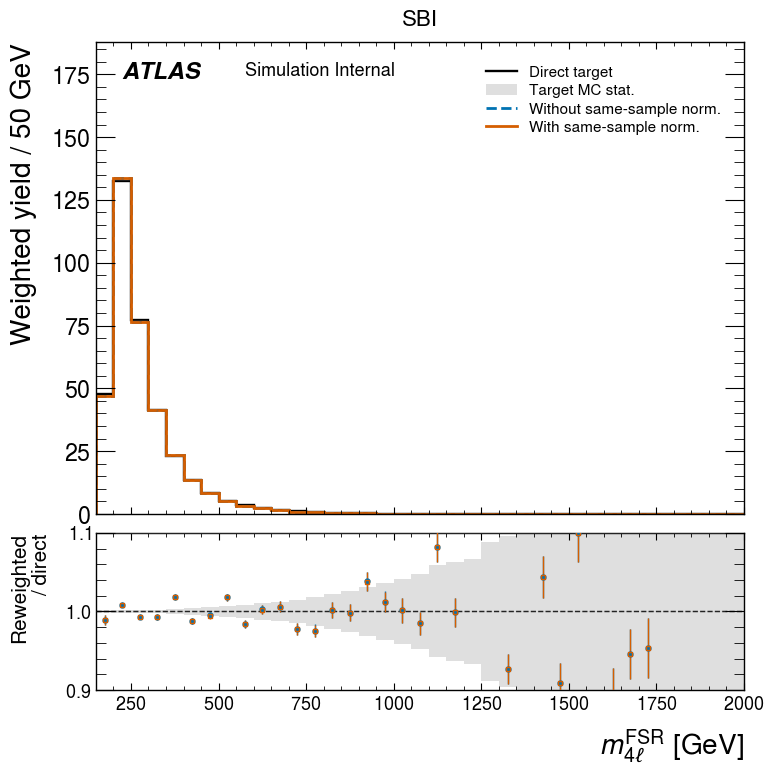

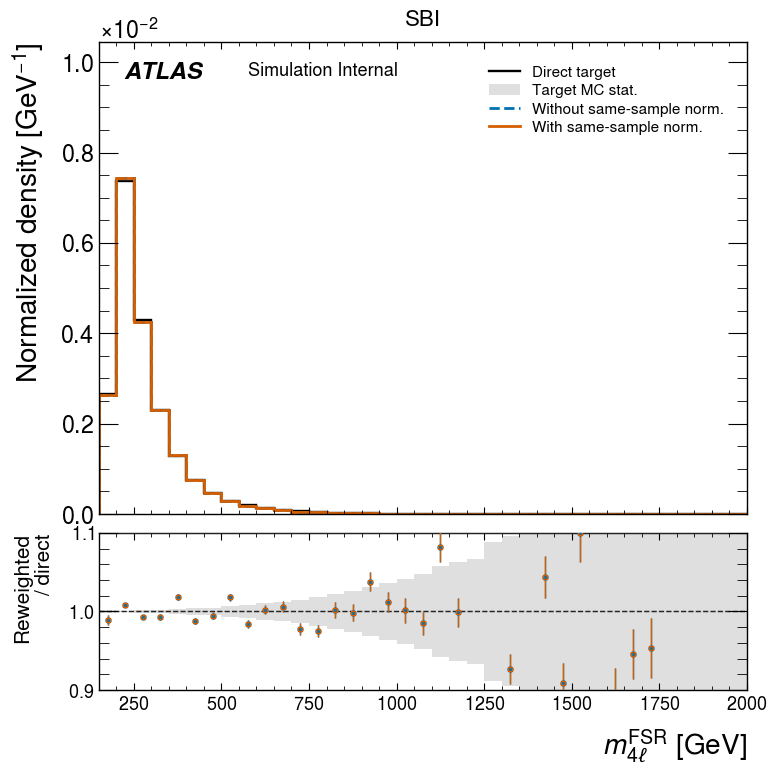

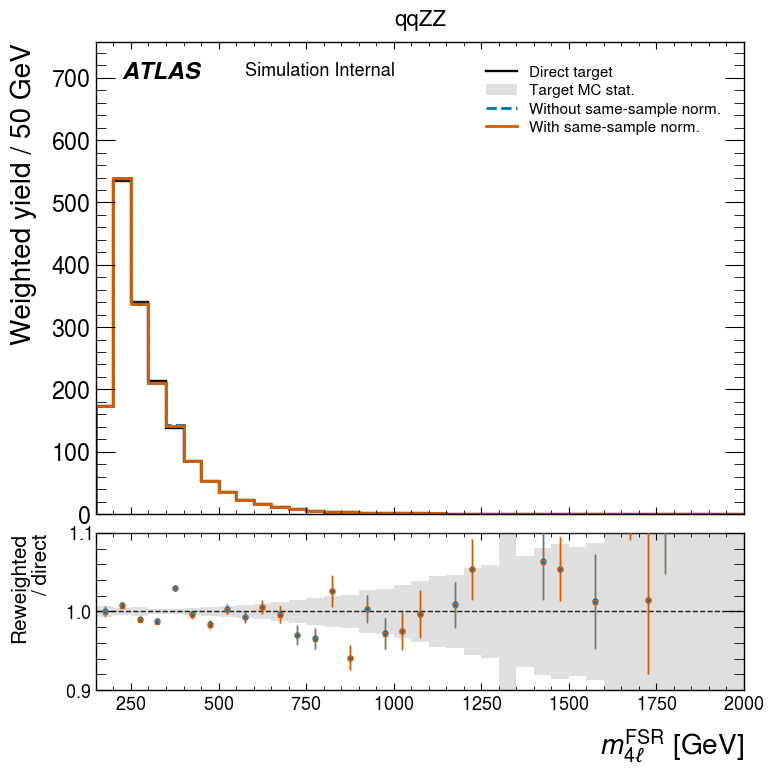

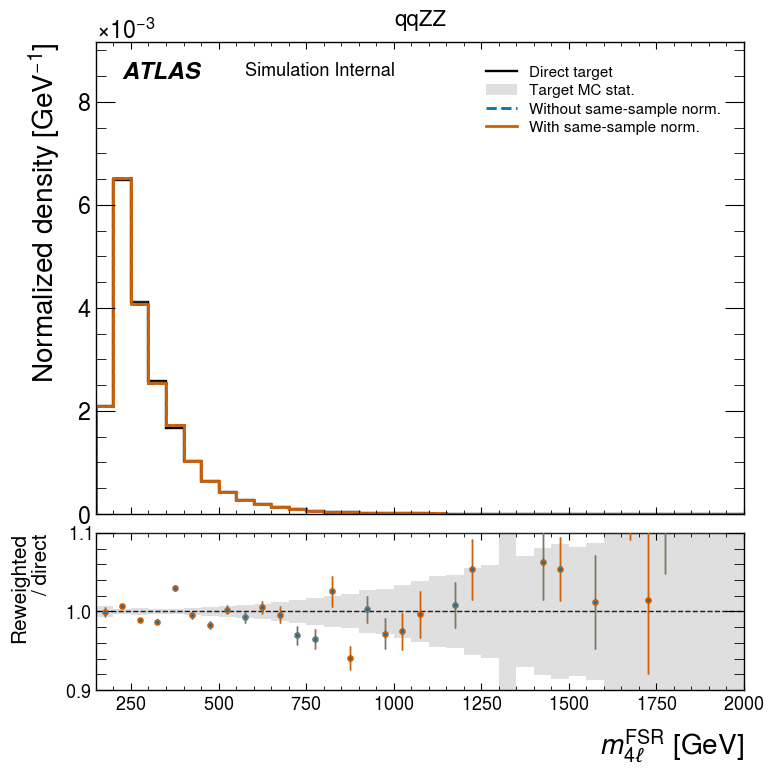

Figures saved to: /content/drive/MyDrive/Colab Notebooks/HZZ_OffShell/plots/03_same_sample_normalization


In [7]:
range_closure = []
for variable, bins, xlabel, yield_label, density_label in variables:
    x_ref = data[variable][reference]
    for tag, name, direct_mask, raw_weights, ssn_weights, components in comparisons:
        x_direct = data[variable][direct_mask]
        w_direct = weights[direct_mask]

        h_direct = np.histogram(x_direct, bins=bins, weights=w_direct)[0]
        v_direct = np.histogram(x_direct, bins=bins, weights=w_direct**2)[0]
        h_raw = np.histogram(x_ref, bins=bins, weights=raw_weights)[0]
        v_raw = np.histogram(x_ref, bins=bins, weights=raw_weights**2)[0]
        h_ssn = np.histogram(x_ref, bins=bins, weights=ssn_weights)[0]
        covariance_ssn = same_sample_covariance(x_ref, bins, components)
        v_ssn = np.maximum(np.diag(covariance_ssn), 0.0)

        for region, ref_region, direct_region in [
            ("Below range", x_ref < bins[0], x_direct < bins[0]),
            ("In range", (x_ref >= bins[0]) & (x_ref <= bins[-1]),
             (x_direct >= bins[0]) & (x_direct <= bins[-1])),
            ("Above range", x_ref > bins[-1], x_direct > bins[-1]),
        ]:
            direct_yield = w_direct[direct_region].sum()
            raw_yield = raw_weights[ref_region].sum()
            ssn_yield = ssn_weights[ref_region].sum()
            range_closure.append({
                "variable": variable, "sample": name, "region": region,
                "direct_yield": direct_yield, "without_SSN": raw_yield, "with_SSN": ssn_yield,
                "without/direct": raw_yield / direct_yield if direct_yield != 0 else np.nan,
                "with/direct": ssn_yield / direct_yield if direct_yield != 0 else np.nan,
            })

        for mode in ("yields", "normalized"):
            raw_plot, ssn_plot, direct_plot = h_raw, h_ssn, h_direct
            raw_variance, ssn_variance, direct_variance = v_raw, v_ssn, v_direct
            ylabel = yield_label
            if mode == "normalized":
                if h_raw.sum() == 0 or h_ssn.sum() == 0 or h_direct.sum() == 0:
                    print(f"Skipping {variable}, {name}: zero in-range signed yield")
                    continue
                raw_plot, raw_variance = normalize_histogram(h_raw, v_raw, bins)
                ssn_plot, ssn_variance = normalize_histogram(h_ssn, covariance_ssn, bins)
                direct_plot, direct_variance = normalize_histogram(h_direct, v_direct, bins)
                ylabel = density_label

            fig, axes = plot_normalization_comparison(
                raw_plot, ssn_plot, direct_plot,
                raw_variance, ssn_variance, direct_variance, bins,
                xlabel=xlabel, ylabel=ylabel, title=name, ratio_ylim=RATIO_YLIM,
            )
            for extension in ("png", "pdf"):
                fig.savefig(PLOT_DIR / f"{variable}_{tag}_{mode}.{extension}",
                            dpi=180, bbox_inches="tight")
            plt.show()
            plt.close(fig)

print(f"Figures saved to: {PLOT_DIR}")

## Check yields inside and outside the plotting ranges

The three regions sum to the full selected-sample yields. Same-sample normalization uses the full reference sample, so it does not enforce yield closure separately inside each plotting range. Underflow and overflow are not folded into edge bins; the final bin includes its right edge.

In [8]:
display(pd.DataFrame(range_closure).set_index(["variable", "sample", "region"]))

direct_yield  without_SSN     with_SSN  \
variable    sample     region                                                
NN_disc_New SBI + qqZZ Below range      0.000000     0.000000     0.000000   
                       In range      2008.875271  2010.416457  2008.892417   
                       Above range      1.728552     1.712592     1.711405   
            SBI        Below range      0.000000     0.000000     0.000000   
                       In range       358.809081   358.888997   358.812277   
                       Above range      0.476871     0.473777     0.473675   
            qqZZ       Below range      0.000000     0.000000     0.000000   
                       In range      1650.066189  1651.527460  1650.080140   
                       Above range      1.251681     1.238816     1.237730   
m4l_fsr     SBI + qqZZ Below range      0.000000     0.000000     0.000000   
                       In range      2010.603823  2012.129049  2010.603823   
                       Above range      0.000000     0.000000     0.000000   
            SBI        Below range      0.000000     0.000000     0.000000   
                       In range       359.285953   359.362774   359.285953   
                       Above range      0.000000     0.000000     0.000000   
            qqZZ       Below range      0.000000     0.000000     0.000000   
                       In range      1651.317870  1652.766275  1651.317870   
                       Above range      0.000000     0.000000     0.000000   

                                    without/direct  with/direct  
variable    sample     region                                    
NN_disc_New SBI + qqZZ Below range             NaN          NaN  
                       In range           1.000767     1.000009  
                       Above range        0.990767     0.990080  
            SBI        Below range             NaN          NaN  
                       In range           1.000223     1.000009  
                       Above range        0.993510     0.993298  
            qqZZ       Below range             NaN          NaN  
                       In range           1.000886     1.000008  
                       Above range        0.989722     0.988854  
m4l_fsr     SBI + qqZZ Below range             NaN          NaN  
                       In range           1.000759     1.000000  
                       Above range             NaN          NaN  
            SBI        Below range             NaN          NaN  
                       In range           1.000214     1.000000  
                       Above range             NaN          NaN  
            qqZZ       Below range             NaN          NaN  
                       In range           1.000877     1.000000  
                       Above range             NaN          NaN